# 5 - Runtime detector and inference pipeline

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

repo root: /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback
python:   3.14.4 -> /Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/venv/bin/python


In [2]:
import itertools
import json
import time

import numpy as np

from perception.contracts import DetectionFrame, FrameStamp
from perception.inference import (
    Frame,
    load_detections,
    prerecorded_frames,
    render_overlay,
    run_inference,
)
from perception.inference import detector as detector_module
from perception.inference.yolo import YoloDetector
from perception.ontology import load_ontology

import html

import matplotlib.pyplot as plt
from IPython.display import HTML, display

In [3]:
def table(rows, columns=None):
    if not rows:
        print("(no rows)")
        return
    columns = columns or list(rows[0])
    head = "".join(
        f"<th style='text-align:left'>{html.escape(str(c))}</th>" for c in columns
    )
    body = "".join(
        "<tr>"
        + "".join(
            f"<td style='text-align:left'>{html.escape(str(r.get(c, '')))}</td>"
            for c in columns
        )
        + "</tr>"
        for r in rows
    )
    display(HTML(f"<table><tr>{head}</tr>{body}</table>"))

In [4]:
def show_images(images, titles=(), columns=4, size=4.0):
    rows = (len(images) + columns - 1) // columns
    figure, axes = plt.subplots(
        rows, columns, figsize=(size * columns, size * rows), squeeze=False
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, list(titles) + [""] * len(images)):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
    figure.tight_layout()
    plt.show()

In [ ]:
WEIGHTS = Path("runs/detector/notebook_yolo26n_seg/weights/best.pt")
EPISODE = Path("captures/curriculum_run/rgb/curriculum-0108")  # a test-split episode
DEVICE = "auto"        # auto / mps / cpu / cuda:0
FRAME = 99             # the frame examined in detail (8 detections, 4 classes)
OUTPUT = Path("runs/inference") / time.strftime("%Y%m%d-%H%M%S")  # new folder per run, never overwritten
ONTOLOGY = load_ontology("configs/ontology.json")
frames = list(prerecorded_frames(EPISODE))
print(f"{EPISODE}: {len(frames)} frames of {frames[0].image.shape}, weights {'found' if WEIGHTS.is_file() else 'MISSING'}")

captures/curriculum_run/rgb/curriculum-0108: 430 frames of (256, 256, 3), weights found


In [7]:
yolo = YoloDetector(WEIGHTS, device=DEVICE)
table([{"detector": yolo.name, "version": yolo.version, "device": yolo.device, "classes": len(yolo.class_names)}])
print("classes:", ", ".join(yolo.class_names))

detector,version,device,classes
ultralytics_yolo_segmentation,8.4.102,mps,28


classes: GoodGoal, GoodGoalMulti, jul_blocks, DecayGoal, DecayGoalEpEnding, RipenGoal, RipenGoalEpEnding, BadGoal, BadGoalMulti, DecoyGoal, Wall, WallTransparent, Ramp, RampOld, LightBlock, HollowBox, HeavyBlock, CylinderTunnel, CylinderTunnelTransparent, DeathZone, HotZone, DataZone, SignBoard, SpawnerButton, SpawnerContainerShort, SpawnerDispenserTall, SpawnerTree, unknown_object


In [8]:
frame = frames[FRAME]
detection = yolo.detect(frame)
rows = []
for k, item in enumerate(detection.frame.objects):
    b = item.bounding_box
    rows.append({
        "id": item.detector_id,
        "classes": ", ".join(f"{e.label} {e.probability:.2f}" for e in item.semantic_distribution.entries),
        "unknown": f"{item.semantic_distribution.unknown_probability:.2f}",
        "confidence": f"{item.confidence:.2f}",
        "entropy": f"{item.uncertainty.entropy:.2f}",
        "box (x0,y0,x1,y1) px": f"{b.x_min:.1f}, {b.y_min:.1f}, {b.x_max:.1f}, {b.y_max:.1f}",
        "centre (norm)": f"{item.normalized_location.x:.3f}, {item.normalized_location.y:.3f}",
        "mask px": int((detection.masks == item.instance_mask.instance_value).sum()) if item.instance_mask else "none",
        "mask file": item.instance_mask.path if item.instance_mask else "",
    })
print(f"frame {frame.stamp.frame_index} @ {frame.stamp.timestamp_seconds:.2f}s: {len(rows)} detections;",
      {k: round(v, 2) for k, v in {"preprocess_ms": detection.timing.preprocess_ms, "inference_ms": detection.timing.inference_ms,
                                    "postprocess_ms": detection.timing.postprocess_ms}.items()})
table(rows)

frame 99 @ 5.94s: 8 detections; {'preprocess_ms': 0.63, 'inference_ms': 12.41, 'postprocess_ms': 16.98}


id,classes,unknown,confidence,entropy,"box (x0,y0,x1,y1) px",centre (norm),mask px,mask file
det_0000,SpawnerContainerShort 0.93,0.07,0.93,0.26,"44.3, 111.2, 76.8, 135.5","0.237, 0.482",739,masks/curriculum-0108/000099.png
det_0001,SpawnerDispenserTall 0.85,0.15,0.85,0.42,"145.9, 29.6, 196.2, 141.8","0.668, 0.335",4893,masks/curriculum-0108/000099.png
det_0002,GoodGoalMulti 0.74,0.26,0.74,0.57,"207.6, 119.1, 228.4, 136.7","0.852, 0.500",295,masks/curriculum-0108/000099.png
det_0003,GoodGoalMulti 0.56,0.44,0.56,0.69,"191.7, 115.5, 209.5, 137.3","0.784, 0.494",284,masks/curriculum-0108/000099.png
det_0004,SpawnerTree 0.55,0.45,0.55,0.69,"192.7, 70.9, 212.4, 104.7","0.791, 0.343",362,masks/curriculum-0108/000099.png
det_0005,GoodGoalMulti 0.54,0.46,0.54,0.69,"247.6, 119.4, 256.0, 136.5","0.984, 0.500",123,masks/curriculum-0108/000099.png
det_0006,GoodGoalMulti 0.52,0.48,0.52,0.69,"202.6, 82.9, 215.2, 98.9","0.816, 0.355",113,masks/curriculum-0108/000099.png
det_0007,GoodGoalMulti 0.40,0.60,0.40,0.67,"191.9, 113.0, 209.5, 137.1","0.784, 0.489",29,masks/curriculum-0108/000099.png


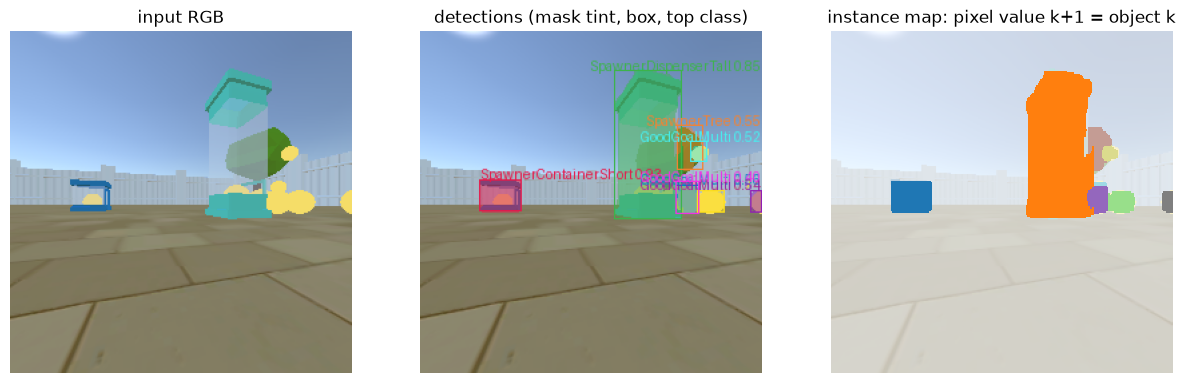

In [9]:
instance_map = np.ma.masked_equal(detection.masks if detection.masks is not None else np.zeros(frame.image.shape[:2]), 0)
figure, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(frame.image); axes[0].set_title("input RGB")
axes[1].imshow(render_overlay(frame.image, detection)); axes[1].set_title("detections (mask tint, box, top class)")
axes[2].imshow(frame.image, alpha=0.35); axes[2].imshow(instance_map, cmap="tab20", interpolation="nearest")
axes[2].set_title("instance map: pixel value k+1 = object k")
for ax in axes:
    ax.axis("off")
plt.show()

In [10]:
payload = detection.frame.to_json()
print("\n".join(payload.splitlines()[:70]), "\n..." if payload.count("\n") > 70 else "")
assert DetectionFrame.from_json(payload) == detection.frame
print(f"\nre-imported identically ({len(payload)} characters)")

{
  "image_height": 256,
  "image_width": 256,
  "objects": [
    {
      "bounding_box": {
        "image_height": 256,
        "image_width": 256,
        "x_max": 76.83879089355469,
        "x_min": 44.268585205078125,
        "y_max": 135.53182983398438,
        "y_min": 111.15629577636719
      },
      "confidence": 0.9281885623931885,
      "detector_id": "det_0000",
      "instance_mask": {
        "encoding": "png",
        "height": 256,
        "instance_value": 1,
        "path": "masks/curriculum-0108/000099.png",
        "width": 256
      },
      "normalized_location": {
        "x": 0.2365378439426422,
        "y": 0.4818127453327179
      },
      "semantic_distribution": {
        "entries": [
          {
            "label": "SpawnerContainerShort",
            "probability": 0.9281885623931885
          }
        ],
        "unknown_probability": 0.07181143760681152
      },
      "source": {
        "configuration_id": "runs/detector/notebook_yolo26n_seg/weights/b

## YOLO on captured frames

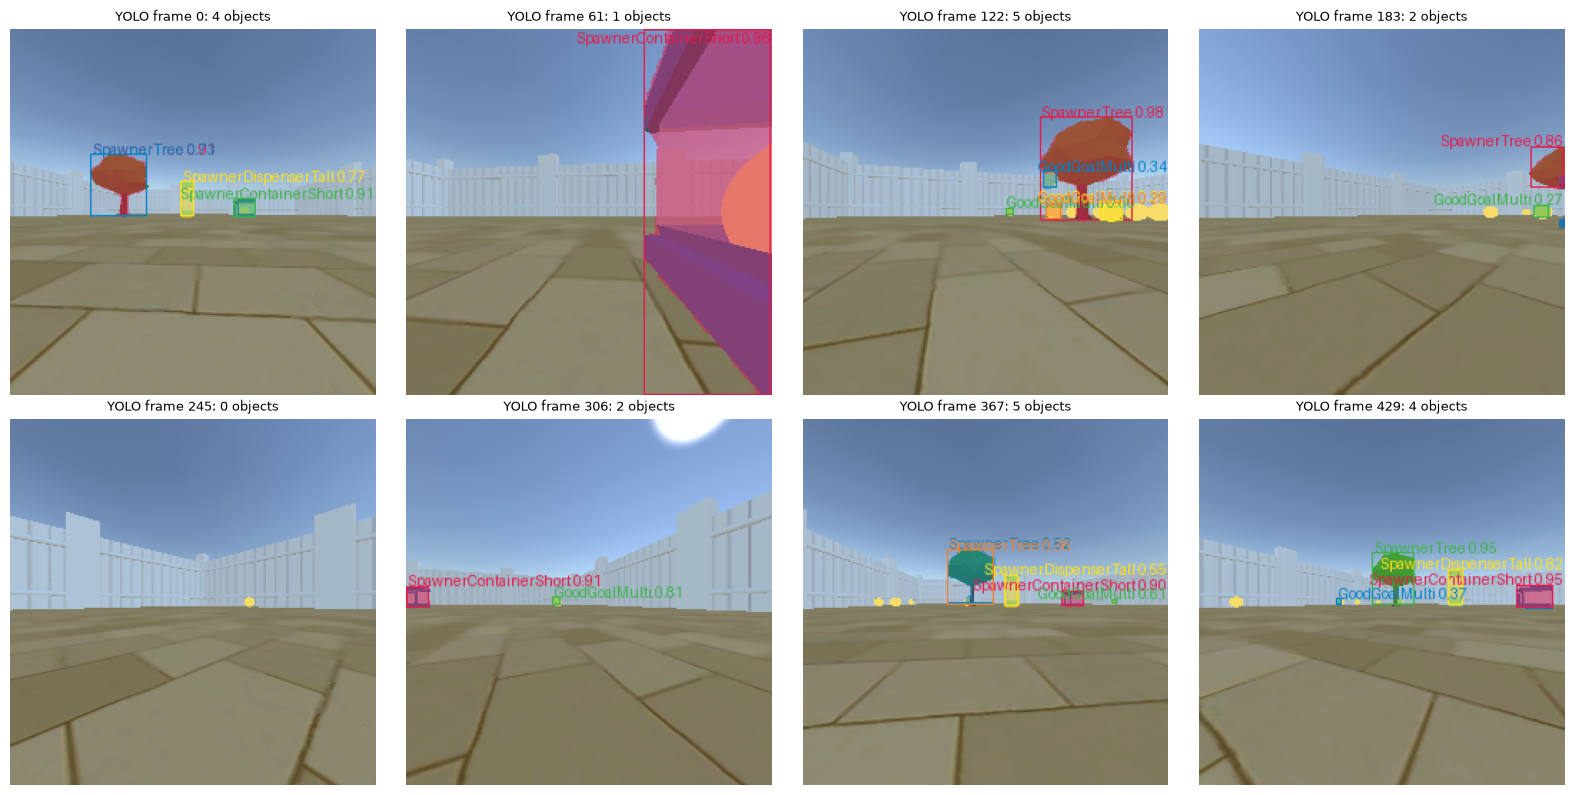

In [11]:
picks = [frames[i] for i in np.linspace(0, len(frames) - 1, 8).astype(int)]
yolo_out = yolo.detect_batch(picks)
show_images([render_overlay(f.image, d) for f, d in zip(picks, yolo_out)],
            [f"YOLO frame {f.stamp.frame_index}: {len(d.frame.objects)} objects" for f, d in zip(picks, yolo_out)])

In [12]:
sample = frames[100:108]
batched = [d.frame for d in yolo.detect_batch(sample)]
single = [yolo.detect(f).frame for f in sample]
box_diff = max((abs(a.bounding_box.x_min - b.bounding_box.x_min) for fa, fb in zip(batched, single)
                for a, b in zip(fa.objects, fb.objects)), default=0.0)
same_labels = all([o.semantic_distribution.entries[0].label for o in fa.objects] == [o.semantic_distribution.entries[0].label for o in fb.objects]
                  for fa, fb in zip(batched, single))
print(f"batched vs single ({yolo.device}): same objects and labels: {same_labels}; max box difference {box_diff:.2e} px")

det_a = YoloDetector(WEIGHTS, deterministic=True)
det_b = YoloDetector(WEIGHTS, deterministic=True)
run_a = [d.frame for d in det_a.detect_batch(sample)]
run_b = [d.frame for d in det_b.detect_batch(sample)]
print(f"deterministic mode on {det_a.device}: two fresh detectors give identical output: {run_a == run_b}")

batched vs single (mps): same objects and labels: True; max box difference 1.53e-05 px


deterministic mode on cpu: two fresh detectors give identical output: True


In [13]:
blank = [Frame(FrameStamp("blank", i, i * 0.06), np.full((256, 256, 3), value, np.uint8)) for i, value in enumerate((0, 128, 255))]
for frame_, result in zip(blank, yolo.detect_batch(blank)):
    print(f"uniform frame value {frame_.image[0, 0, 0]:3d}: {len(result.frame.objects)} objects, masks={result.masks}, "
          f"valid contract: {DetectionFrame.from_json(result.frame.to_json()) == result.frame}")

uniform frame value   0: 0 objects, masks=None, valid contract: True
uniform frame value 128: 0 objects, masks=None, valid contract: True
uniform frame value 255: 0 objects, masks=None, valid contract: True


In [14]:
summary = run_inference(yolo, prerecorded_frames(EPISODE), OUTPUT, ontology=ONTOLOGY, visualize=True)
print(json.dumps({k: v for k, v in summary.items() if k != "latency_ms"}, indent=2))
table([{"stage": stage, **{k: f"{v:.2f}" for k, v in stats.items()}} for stage, stats in summary["latency_ms"].items() if stats])
for path in sorted(OUTPUT.iterdir()):
    print(f"  {path.name:20s} {sum(1 for _ in path.rglob('*')) if path.is_dir() else path.stat().st_size} {'files' if path.is_dir() else 'bytes'}")
written = load_detections(OUTPUT / "detections.jsonl")
print(f"re-read {len(written)} DetectionFrames from detections.jsonl")

{
  "detector": {
    "name": "ultralytics_yolo_segmentation",
    "version": "8.4.102",
    "device": "mps"
  },
  "batch_size": 1,
  "frames": 430,
  "empty_frames": 28,
  "detections": 1486,
  "throughput": {
    "detector_fps": 43.682960495373614,
    "end_to_end_fps": 28.93771377291566,
    "wall_seconds": 14.85950145800598
  }
}


stage,mean,p50,p95,max
per_frame_wall,22.89,22.07,30.36,78.92
preprocess,0.74,0.69,1.30,9.69
inference,13.55,12.79,16.83,54.09
postprocess,8.16,8.02,12.49,59.50


  detections.jsonl     1556063 bytes
  masks                403 files
  overlays             431 files
  summary.json         1029 bytes
  timing.jsonl         83506 bytes


re-read 430 DetectionFrames from detections.jsonl


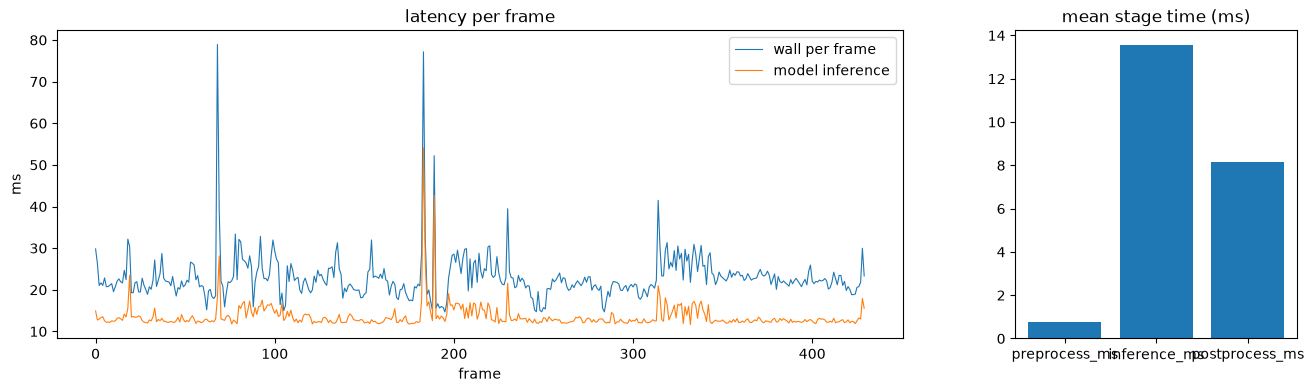

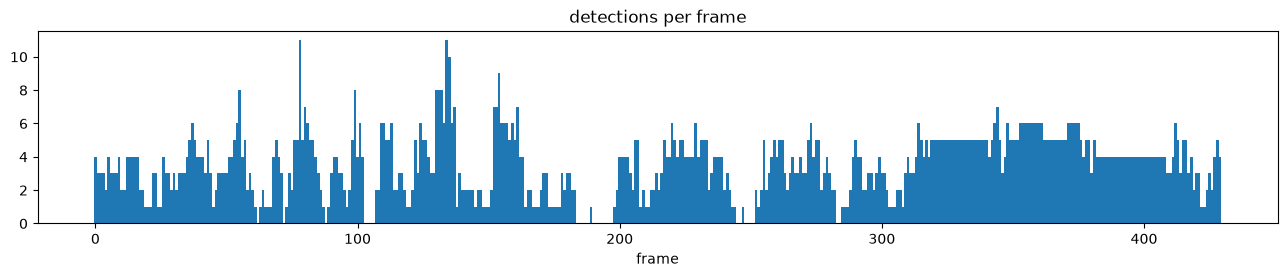

In [15]:
timing = [json.loads(line) for line in (OUTPUT / "timing.jsonl").read_text().splitlines()]
figure, (left, right) = plt.subplots(1, 2, figsize=(16, 4), width_ratios=(3, 1))
left.plot([t["frame_index"] for t in timing], [t["wall_ms"] for t in timing], linewidth=0.8, label="wall per frame")
left.plot([t["frame_index"] for t in timing], [t["inference_ms"] for t in timing], linewidth=0.8, label="model inference")
left.set_xlabel("frame"); left.set_ylabel("ms"); left.legend(); left.set_title("latency per frame")
stages = ["preprocess_ms", "inference_ms", "postprocess_ms"]
right.bar(stages, [np.mean([t[s] for t in timing]) for s in stages]); right.set_title("mean stage time (ms)")
plt.show()
counts = [len(d.objects) for d in written]
plt.figure(figsize=(16, 2.5)); plt.bar(range(len(counts)), counts, width=1.0); plt.title("detections per frame"); plt.xlabel("frame"); plt.show()

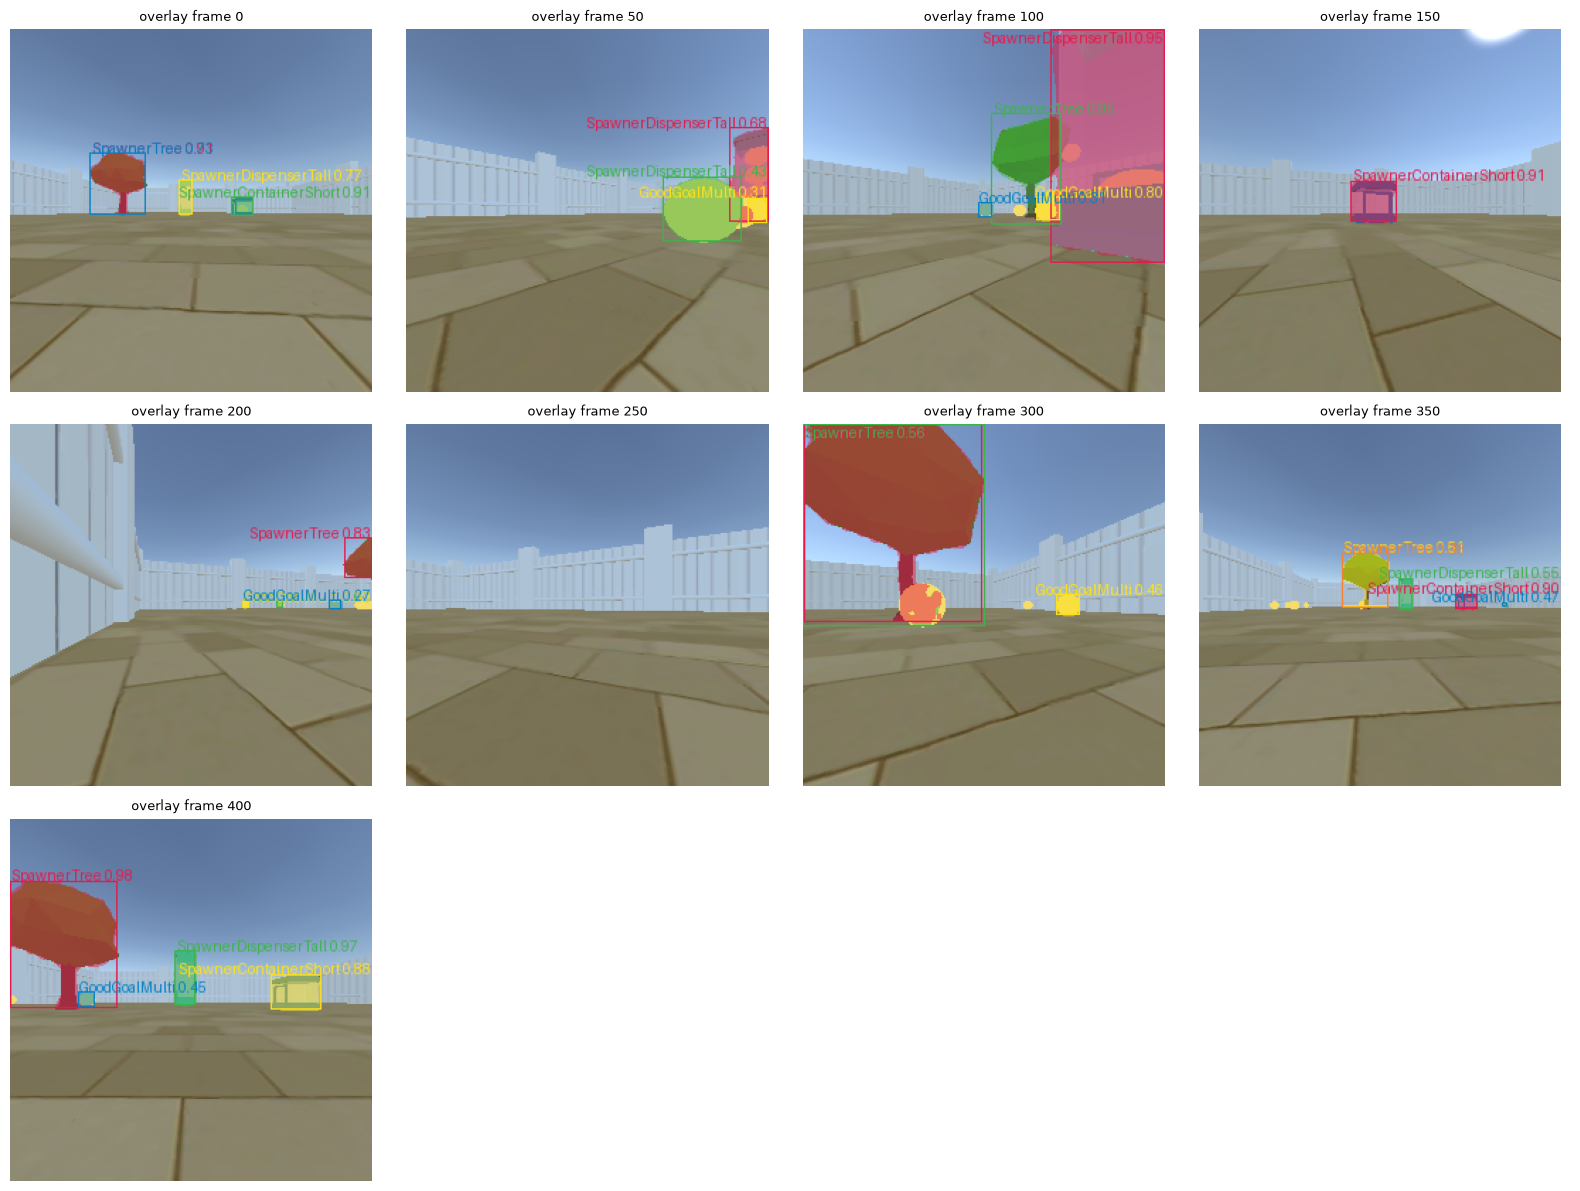

In [16]:
show_images([plt.imread(OUTPUT / "overlays" / EPISODE.name / f"{i:06d}.png") for i in range(0, len(frames), 50)],
            [f"overlay frame {i}" for i in range(0, len(frames), 50)])

## Latency and throughput by device and batch size

device,batch,detector fps,end-to-end fps,p50 ms/frame,p95 ms/frame
mps,1,43.5,43.5,22.2,29.3
mps,4,67.3,67.3,12.5,17.7
mps,16,81.7,81.7,9.1,34.6
cpu (deterministic),1,45.2,45.2,21.8,24.6
cpu (deterministic),4,53.0,53.0,18.1,21.6
cpu (deterministic),16,25.4,25.4,39.7,45.2


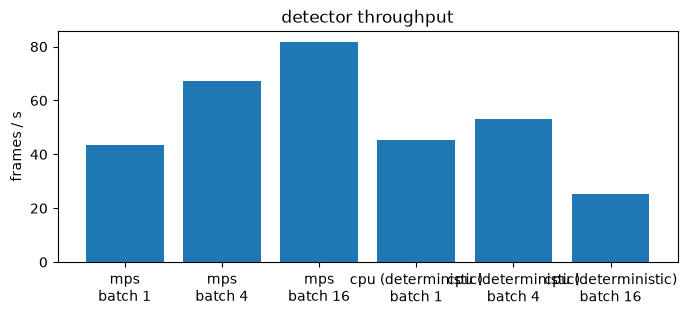

In [17]:
rows = []
sweep_frames = frames[:120]
for label, det in ((yolo.device, yolo), ("cpu (deterministic)", det_a)):
    for batch in (1, 4, 16):
        s = run_inference(det, sweep_frames, batch_size=batch)
        rows.append({"device": label, "batch": batch, "detector fps": round(s["throughput"]["detector_fps"], 1),
                     "end-to-end fps": round(s["throughput"]["end_to_end_fps"], 1),
                     "p50 ms/frame": round(s["latency_ms"]["per_frame_wall"]["p50"], 1),
                     "p95 ms/frame": round(s["latency_ms"]["per_frame_wall"]["p95"], 1)})
table(rows)
plt.figure(figsize=(8, 3))
labels = [f"{r['device']}\nbatch {r['batch']}" for r in rows]
plt.bar(labels, [r["detector fps"] for r in rows]); plt.ylabel("frames / s"); plt.title("detector throughput"); plt.show()